In [1]:
import numpy as np
import matplotlib.pyplot as plt

url = 'https://lectures.scientific-python.org/_downloads/087d8fe936fcb7a4762b9850b932cf9e/populations.txt'
data = np.loadtxt(url)

years = data[:, 0].astype(int)
hares = data[:, 1]
lynxes = data[:, 2]
carrots = data[:, 3]

1) Plot the population size of each species for each year on a single graph. Add legend and axis labels to the plot.

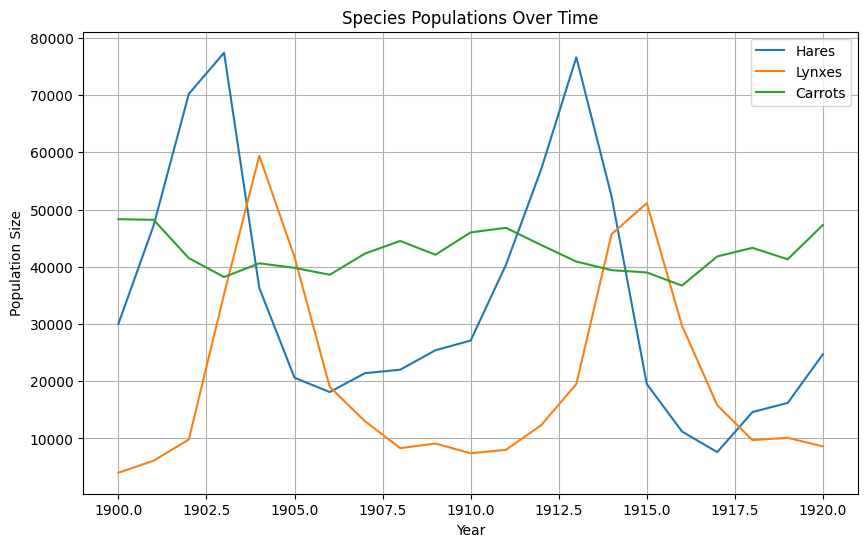

In [2]:
plt.figure(figsize=(10, 6))
plt.plot(years, hares, label='Hares')
plt.plot(years, lynxes, label='Lynxes')
plt.plot(years, carrots, label='Carrots')

plt.xlabel('Year')
plt.ylabel('Population Size')
plt.title('Species Populations Over Time')
plt.legend()
plt.grid(True)
plt.show()

2) Find which year each species had the largest population. Mark these years in the plot of populations.

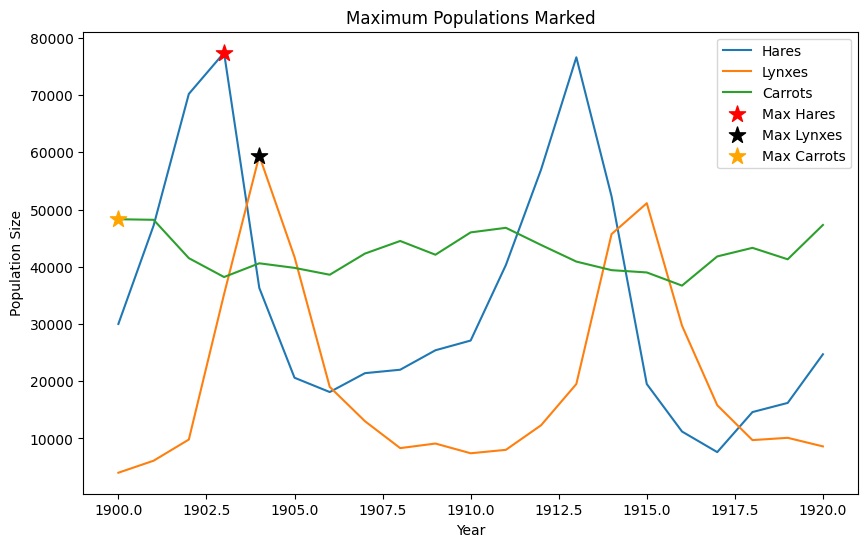

In [3]:
idx_h = np.argmax(hares)
idx_l = np.argmax(lynxes)
idx_c = np.argmax(carrots)

plt.figure(figsize=(10, 6))
plt.plot(years, hares, label='Hares')
plt.plot(years, lynxes, label='Lynxes')
plt.plot(years, carrots, label='Carrots')

plt.scatter(years[idx_h], hares[idx_h], color='red', marker='*', s=150, zorder=5, label='Max Hares')
plt.scatter(years[idx_l], lynxes[idx_l], color='black', marker='*', s=150, zorder=5, label='Max Lynxes')
plt.scatter(years[idx_c], carrots[idx_c], color='orange', marker='*', s=150, zorder=5, label='Max Carrots')

plt.xlabel('Year')
plt.ylabel('Population Size')
plt.title('Maximum Populations Marked')
plt.legend()
plt.show()

3) Assuming total population of hares and lynxes is 100%, plot stacked bar graph showing ratio of each specis for each year in the period.

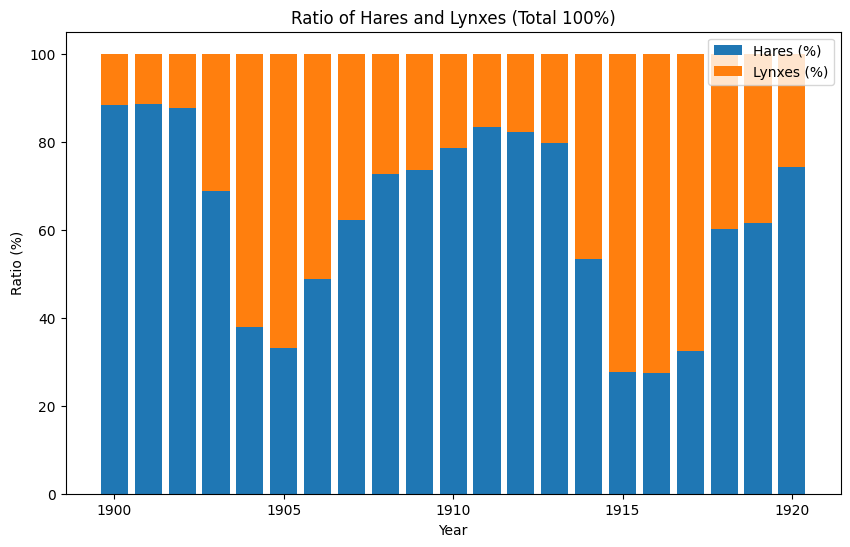

In [4]:
total_hl = hares + lynxes
hare_ratio = (hares / total_hl) * 100
lynx_ratio = (lynxes / total_hl) * 100

plt.figure(figsize=(10, 6))
plt.bar(years, hare_ratio, label='Hares (%)')
plt.bar(years, lynx_ratio, bottom=hare_ratio, label='Lynxes (%)')

plt.xlabel('Year')
plt.ylabel('Ratio (%)')
plt.title('Ratio of Hares and Lynxes (Total 100%)')
plt.legend()
plt.show()

4) Find the mean and std of the populations of each species. Plot the historgam of population for each species and show mean values with vertical line. Show each histogram in a separate plot. Arrange 3 plots in a row.

Hares  - Mean: 34080.95, Std: 20897.91
Lynxes - Mean: 20166.67, Std: 16254.59
Carrots- Mean: 42400.00, Std: 3322.51


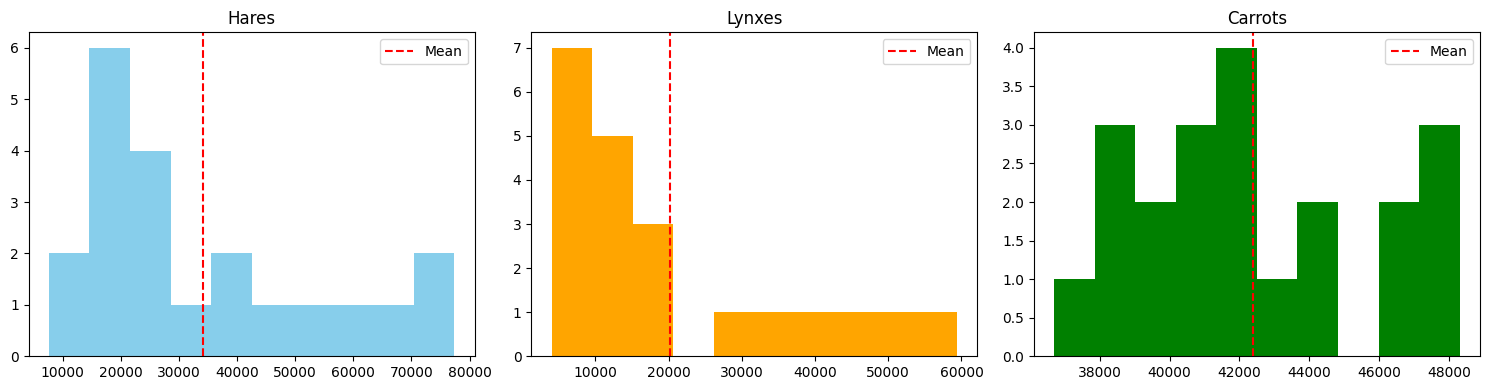

In [5]:
print(f"Hares  - Mean: {np.mean(hares):.2f}, Std: {np.std(hares):.2f}")
print(f"Lynxes - Mean: {np.mean(lynxes):.2f}, Std: {np.std(lynxes):.2f}")
print(f"Carrots- Mean: {np.mean(carrots):.2f}, Std: {np.std(carrots):.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(hares, bins=10, color='skyblue')
axes[0].axvline(np.mean(hares), color='red', linestyle='--', label='Mean')
axes[0].set_title('Hares')
axes[0].legend()

axes[1].hist(lynxes, bins=10, color='orange')
axes[1].axvline(np.mean(lynxes), color='red', linestyle='--', label='Mean')
axes[1].set_title('Lynxes')
axes[1].legend()

axes[2].hist(carrots, bins=10, color='green')
axes[2].axvline(np.mean(carrots), color='red', linestyle='--', label='Mean')
axes[2].set_title('Carrots')
axes[2].legend()

plt.tight_layout()
plt.show()

5) Find which species (hares or lynxes) has the largest population for each year. Print the result as [H, H, L, H, ...]. Plot a pie chart showing the ratio of "H" and "L" values.

Result: [np.str_('H'), np.str_('H'), np.str_('H'), np.str_('H'), np.str_('L'), np.str_('L'), np.str_('L'), np.str_('H'), np.str_('H'), np.str_('H'), np.str_('H'), np.str_('H'), np.str_('H'), np.str_('H'), np.str_('H'), np.str_('L'), np.str_('L'), np.str_('L'), np.str_('H'), np.str_('H'), np.str_('H')]


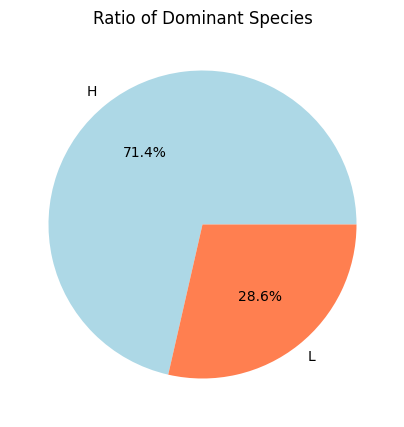

In [6]:
who_is_bigger = np.where(hares > lynxes, 'H', 'L')
print("Result:", list(who_is_bigger))

count_h = np.sum(who_is_bigger == 'H')
count_l = np.sum(who_is_bigger == 'L')

plt.figure(figsize=(5, 5))
plt.pie([count_h, count_l], labels=['H', 'L'], autopct='%1.1f%%', colors=['lightblue', 'coral'])
plt.title('Ratio of Dominant Species')
plt.show()

6) Plot the change in the hare population and in the lynx population for each year. Find the correlation coefficient between the both time series.

Correlation coefficient: -0.178


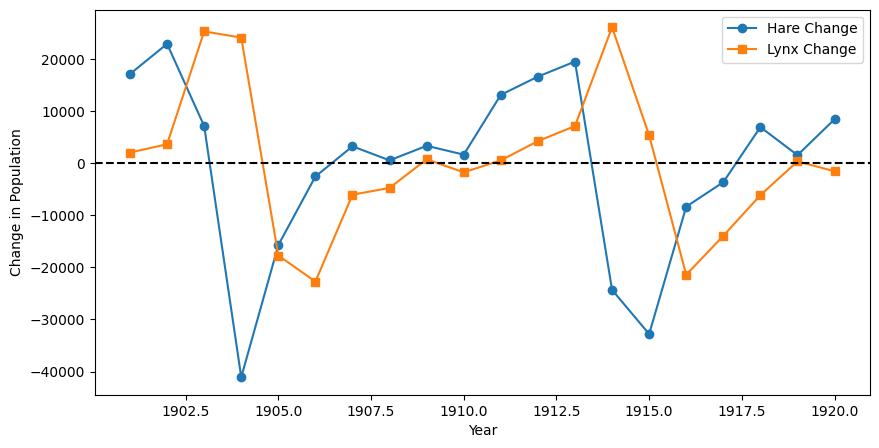

In [7]:
hare_change = np.diff(hares)
lynx_change = np.diff(lynxes)

corr_coef = np.corrcoef(hare_change, lynx_change)[0, 1]
print(f"Correlation coefficient: {corr_coef:.3f}")

plt.figure(figsize=(10, 5))
plt.plot(years[1:], hare_change, label='Hare Change', marker='o')
plt.plot(years[1:], lynx_change, label='Lynx Change', marker='s')

plt.axhline(0, color='black', linestyle='--')
plt.xlabel('Year')
plt.ylabel('Change in Population')
plt.legend()
plt.show()

7) Using a scatter plot, show the population of hares vs lynxes by year (each point corresponds to a particular year, and the point coordinates correspond to the population of the two species in that year).

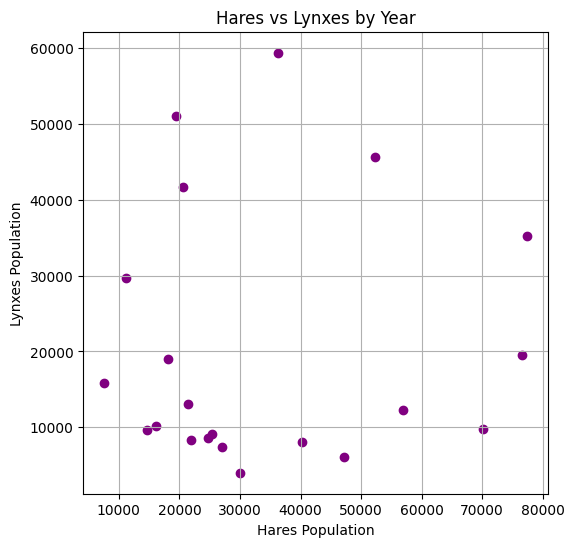

In [8]:
plt.figure(figsize=(6, 6))
plt.scatter(hares, lynxes, color='purple')

plt.xlabel('Hares Population')
plt.ylabel('Lynxes Population')
plt.title('Hares vs Lynxes by Year')
plt.grid(True)
plt.show()

8) Assume the population of hares in 1920 is unknown. Suggest a way to estimate this value. Compare an estimated value with the true value and print a ratio of the error to the true value.

In [9]:
last_5_years = years[-5:]
last_5_hares = hares[-5:]

trend = np.polyfit(last_5_years, last_5_hares, 1)
estimated_hare_1920 = np.polyval(trend, 1920)
true_hare_1920 = hares[-1]

error_ratio = abs(estimated_hare_1920 - true_hare_1920) / true_hare_1920

print(f"Estimated Hares in 1920: {estimated_hare_1920:.2f}")
print(f"True Hares in 1920: {true_hare_1920:.2f}")
print(f"Error to true value ratio: {error_ratio:.4f}")

Estimated Hares in 1920: 21980.00
True Hares in 1920: 24700.00
Error to true value ratio: 0.1101


напишите функцию, реализующую алгоритм k-means.

In [10]:
def k_means(X, k, max_iter=100, threshold=0.001):
    np.random.seed(42)
    
    random_indices = np.random.choice(X.shape[0], k, replace=False)
    centers = X[random_indices]
    
    for step in range(max_iter):
        
        dist = np.linalg.norm(X[:, np.newaxis] - centers, axis=2)
        labels = np.argmin(dist, axis=1)
        
        old_centers = centers.copy()
        new_centers = np.zeros((k, X.shape[1]))
        
        for j in range(k):
            cluster_points = X[labels == j]
            if len(cluster_points) > 0:
                new_centers[j] = np.mean(cluster_points, axis=0)
            else:
                new_centers[j] = centers[j]
                
        centers = new_centers
        shift = np.sum((old_centers - centers) ** 2)
        
        if shift < threshold:
            break
            
    final_dist = np.linalg.norm(X[:, np.newaxis] - centers, axis=2)
    min_dist = np.min(final_dist, axis=1)
    sse = np.sum(min_dist ** 2)
    
    return labels, sse

In [12]:
import sklearn
print("Ура, работает! Версия:", sklearn.__version__)

ModuleNotFoundError: No module named 'sklearn'

In [13]:
import sys
print(sys.executable)

c:\Users\matve\AppData\Local\Programs\Python\Python312\python.exe


In [14]:
import sys
!{sys.executable} -m pip install scikit-learn --user

  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.3 MB 5.6 MB/s eta 0:00:02
   ---------- ----------------------------- 2.1/8.3 MB 6.2 MB/s eta 0:00:01
   ---------------- ----------------------- 3.4/8.3 MB 6.1 MB/s eta 0:00:01
   ---------------------- ----------------- 4.7/8.3 MB 6.2 MB/s eta 0:00:01
   --------------------------- ------------ 5.8/8.3 MB 6.1 MB/s eta 0:00:01
   ---------------------------------- ----- 7.1/8.3 MB 5.9 MB/s eta 0:00:01
   ---------------------------------------- 8.3/8.3 MB 6.1 MB/s eta 0:00:00
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached narwhals-2.27.1-py3-none-any.whl (483 kB)
Using cached threadpoolctl-


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Выделите 10 кластеров в датасете MNIST. Дайте интерпретацию каждому полученному кластеру (к какой цифре его можно отнести). Нарисуйте изображения, которые отвечают центрам кластеров. Посчитайте, сколько из точек кластера действительно являются той цифрой, к которой вы его отнесли (для этого сравните с массивом правильных ответов labels) и нарисуйте матрицу ошибок.

Загружаем MNIST. Ждем...
SSE: 192960.44
Кластер -> Цифра: [0 4 7 2 1 6 7 1 8 3]


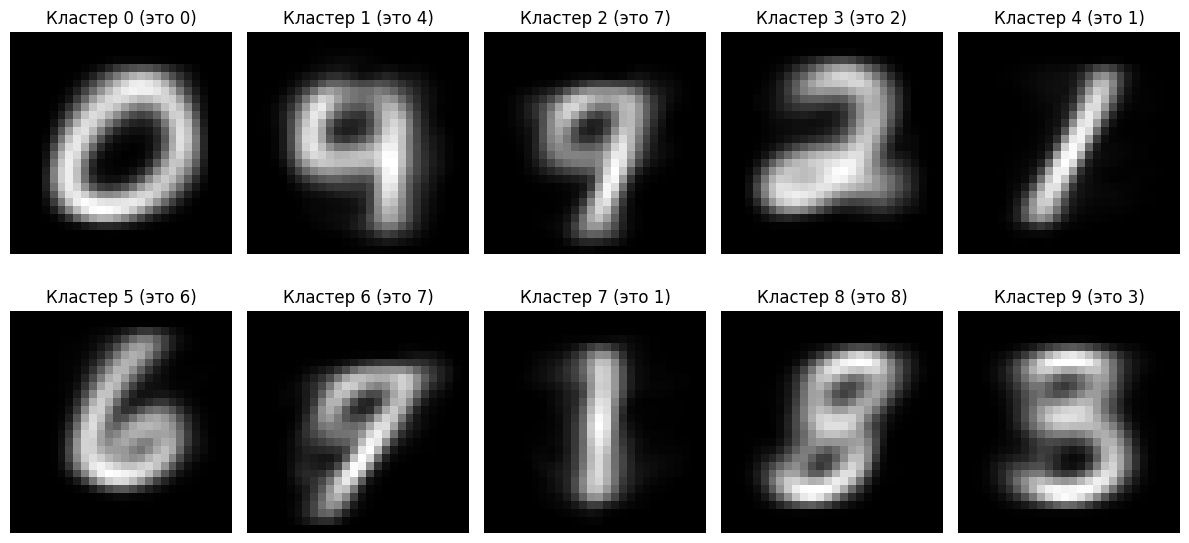

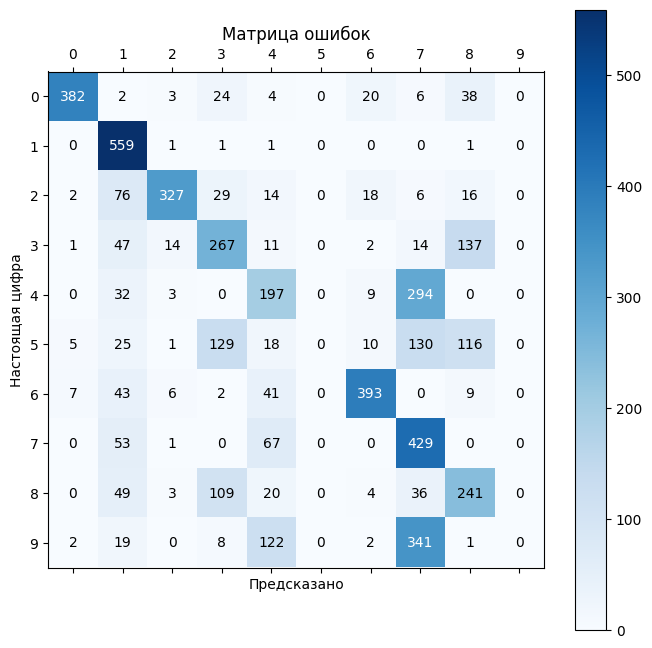

In [15]:
from sklearn.datasets import fetch_openml

def k_means(X, k, max_iter=100, threshold=0.001):
    np.random.seed(42)
    
    random_indices = np.random.choice(X.shape[0], k, replace=False)
    centers = X[random_indices]
    
    for step in range(max_iter):
        dist = np.linalg.norm(X[:, np.newaxis] - centers, axis=2)
        labels = np.argmin(dist, axis=1)
        
        old_centers = centers.copy()
        new_centers = np.zeros((k, X.shape[1]))
        
        for j in range(k):
            cluster_points = X[labels == j]
            if len(cluster_points) > 0:
                new_centers[j] = np.mean(cluster_points, axis=0)
            else:
                new_centers[j] = centers[j]
                
        centers = new_centers
        shift = np.sum((old_centers - centers) ** 2)
        
        if shift < threshold:
            break
            
    final_dist = np.linalg.norm(X[:, np.newaxis] - centers, axis=2)
    min_dist = np.min(final_dist, axis=1)
    sse = np.sum(min_dist ** 2)
    
    return labels, sse

print("Загружаем MNIST. Ждем...")
images, labels_true = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False)

X = images[:5000] / 255.0
y_true = labels_true[:5000].astype(int)

labels_pred, sse = k_means(X, k=10, max_iter=30)
print(f"SSE: {sse:.2f}")

cluster_to_digit = np.zeros(10, dtype=int)

for i in range(10):
    true_labels_in_cluster = y_true[labels_pred == i]
    cluster_to_digit[i] = np.bincount(true_labels_in_cluster).argmax()

print("Кластер -> Цифра:", cluster_to_digit)

fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for i in range(10):
    row = i // 5
    col = i % 5
    
    cluster_images = X[labels_pred == i]
    center_image = np.mean(cluster_images, axis=0).reshape(28, 28)
    
    axes[row, col].imshow(center_image, cmap='gray')
    axes[row, col].set_title(f"Кластер {i} (это {cluster_to_digit[i]})")
    axes[row, col].axis('off')

plt.tight_layout()
plt.show()

predicted_digits = cluster_to_digit[labels_pred]

cm = np.zeros((10, 10), dtype=int)

for i in range(len(y_true)):
    true_val = y_true[i]
    pred_val = predicted_digits[i]
    cm[true_val, pred_val] += 1

plt.figure(figsize=(8, 8))
plt.matshow(cm, cmap='Blues', fignum=1)
plt.colorbar()

plt.xlabel('Предсказано')
plt.ylabel('Настоящая цифра')
plt.xticks(np.arange(10), np.arange(10))
plt.yticks(np.arange(10), np.arange(10))
plt.title('Матрица ошибок')

for i in range(10):
    for j in range(10):
        color = 'white' if cm[i, j] > cm.max() / 2 else 'black'
        plt.text(j, i, str(cm[i, j]), ha='center', va='center', color=color)

plt.show()